<a href="https://colab.research.google.com/github/khushimishra-26/Two-Tower-Recommendation-System/blob/main/TwoTower_Recoomendation_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [74]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', 200)

In [75]:
RATINGS_URL="https://raw.githubusercontent.com/zygmuntz/goodbooks-10k/master/ratings.csv"
BOOKS_URL="https://raw.githubusercontent.com/zygmuntz/goodbooks-10k/master/books.csv"

ratings = pd.read_csv(RATINGS_URL)
books = pd.read_csv(BOOKS_URL)

print("ratings:", ratings.shape)
print("books:", books.shape)

ratings: (5976479, 3)
books: (10000, 23)


In [76]:
ratings.head()

,user_id,book_id,rating
0,1,258,5
1,2,4081,4
2,2,260,5
3,2,9296,5
4,2,2318,3


In [77]:
books.head()

,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,title,language_code,average_rating,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",eng,4.34,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,Harry Potter and the Sorcerer's Stone (Harry P...,eng,4.44,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,"Twilight (Twilight, #1)",en-US,3.57,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,To Kill a Mockingbird,eng,4.25,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,The Great Gatsby,eng,3.89,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


In [78]:
ratings.columns.tolist()

['user_id', 'book_id', 'rating']

In [79]:
books.columns.tolist()

['book_id',
 'goodreads_book_id',
 'best_book_id',
 'work_id',
 'books_count',
 'isbn',
 'isbn13',
 'authors',
 'original_publication_year',
 'original_title',
 'title',
 'language_code',
 'average_rating',
 'ratings_count',
 'work_ratings_count',
 'work_text_reviews_count',
 'ratings_1',
 'ratings_2',
 'ratings_3',
 'ratings_4',
 'ratings_5',
 'image_url',
 'small_image_url']

In [80]:
ratings.isnull().sum()

,0
user_id,0
book_id,0
rating,0


In [81]:
print(ratings['rating'].value_counts().sort_index())

rating
1     124195
2     359257
3    1370916
4    2139018
5    1983093
Name: count, dtype: int64


In [82]:
books.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   book_id                    10000 non-null  int64  
 1   goodreads_book_id          10000 non-null  int64  
 2   best_book_id               10000 non-null  int64  
 3   work_id                    10000 non-null  int64  
 4   books_count                10000 non-null  int64  
 5   isbn                       9300 non-null   object 
 6   isbn13                     9415 non-null   float64
 7   authors                    10000 non-null  object 
 8   original_publication_year  9979 non-null   float64
 9   original_title             9415 non-null   object 
 10  title                      10000 non-null  object 
 11  language_code              8916 non-null   object 
 12  average_rating             10000 non-null  float64
 13  ratings_count              10000 non-null  int6

#### Create an Implicit dataset(likes)

We convert our task from a regression task into a binary classification by defining the following simplified binary label:
*   1 if the rating ≥ 4
*   0 otherwise



In [83]:
# | Filter users by activity |
users_count = ratings['user_id'].value_counts()

# Create a dense dataset by only considering users with between 10 and 1000 ratings
active_users = users_count[(users_count >= 10) & (users_count <= 1000)]
dataset = ratings[ratings['user_id'].isin(active_users)].copy()


# | Filter books by popularity |
book_counts = ratings['book_id'].value_counts()

# Create a dense dataset by only considering books with atleast 50 ratings
popular_books = book_counts[(book_counts >= 50)]
dataset = ratings[ratings['book_id'].isin(popular_books)].copy()


# | Label: Convert rating → implicit like if rating >= 4 |
dataset['label'] = np.where(dataset['rating'] >= 4, 1, 0)

print(dataset.head())

    user_id  book_id  rating  label
0         1      258       5      1
2         2      260       5      1
6         2      315       3      0
8         2      301       5      1
12        4       70       4      1


#### Feature Engineering

In [84]:
# Book features (metadata)
book_feats = books[['book_id', 'original_publication_year', 'authors', 'title', 'language_code']].copy()

book_feats["original_publication_year"] = pd.to_numeric(book_feats["original_publication_year"], errors="coerce")

book_feats["year_bucket"] = ((book_feats["original_publication_year"] // 10) * 10)

book_feats["primary_author"] = (book_feats["authors"].astype(str).str.split(",").str[0].str.strip())


# Merge book metadata
dataset = dataset.merge(book_feats, on="book_id", how="left")

dataset["language_code"] = (
    dataset["language_code"]
    .fillna("UNK")
    .astype(str)
    .str.strip()
)
dataset.loc[dataset["language_code"] == "", "language_code"] = "Unknown"

# Year bucket: add explicit UNK bucket for missing (fine to fill here)
dataset["year_bucket"] = dataset["year_bucket"].fillna(-1).astype(np.int32)

# build author vocabulary
dataset["primary_author"] = (dataset["primary_author"].fillna("Unknown").astype(str))

# Encoding categorical features into numerical features
from sklearn.preprocessing import LabelEncoder

columns = {
    "language_code": "lang_idx",
    "user_id": "user_idx",
    "book_id": "item_idx",
    "year_bucket": "year_idx",
    "primary_author": "author_idx"
}

for col, encoded_col in columns.items():
    encoder = LabelEncoder()
    dataset[encoded_col] = encoder.fit_transform(dataset[col]).astype(np.int64)

display(dataset.tail())

,user_id,book_id,rating,label,original_publication_year,authors,title,language_code,year_bucket,primary_author,lang_idx,user_idx,item_idx,year_idx,author_idx
3007692,49925,330,5,1,1990.0,Robert Jordan,"The Eye of the World (Wheel of Time, #1)",eng,1990,Robert Jordan,5,49924,277,43,822
3007693,49925,510,5,1,1990.0,Robert Jordan,"The Great Hunt (Wheel of Time, #2)",en-US,1990,Robert Jordan,4,49924,457,43,822
3007694,49925,528,4,1,1991.0,Robert Jordan,"The Dragon Reborn (Wheel of Time, #3)",eng,1990,Robert Jordan,5,49924,475,43,822
3007695,49925,722,4,1,1992.0,Robert Jordan,"The Shadow Rising (Wheel of Time, #4)",en-US,1990,Robert Jordan,4,49924,663,43,822
3007696,49925,1023,4,1,1994.0,Robert Jordan,"Lord of Chaos (Wheel of Time, #6)",eng,1990,Robert Jordan,5,49924,902,43,822


In [85]:
num_users = dataset["user_idx"].nunique()
num_items = dataset["item_idx"].nunique()
num_langs = dataset["lang_idx"].nunique()
num_authors = dataset["author_idx"].nunique()
num_year_buckets = dataset["year_idx"].nunique()
num_interactions = len(dataset)

positives = (dataset["label"] == 1).sum()
positive_rate = (dataset["label"] == 1).mean()

unique_user_ids = dataset["user_id"].nunique()
unique_book_ids = dataset["book_id"].nunique()

stats_df = pd.Series({
    "num_users": num_users,
    "num_items": num_items,
    "num_langs": num_langs,
    "num_authors": num_authors,
    "num_year_buckets": num_year_buckets,
    "num_interactions": num_interactions,
    "positives": positives,
    "positive_rate": positive_rate,
    "unique_user_ids": unique_user_ids,
    "unique_book_ids": unique_book_ids,
}).to_frame("Value")

stats_df["Value"] = stats_df["Value"].map(
    lambda x: f"{x:.4f}" if isinstance(x, float) and x <= 1
    else f"{x:,.0f}"
)

display(stats_df)

,Value
num_users,"53,424"
num_items,"1,852"
num_langs,14
num_authors,"1,006"
num_year_buckets,46
num_interactions,"3,007,697"
positives,"2,073,129"
positive_rate,0.6893
unique_user_ids,"53,424"
unique_book_ids,"1,852"


### Train-test split

*   Stratified sampling: class distribution is heavily skewed
*   Stratify by the implicit label: positive rate stays similar across splits, helps with model generalization

In [86]:
from sklearn.model_selection import train_test_split

SEED = 42

train_df, temp_df = train_test_split(
    dataset,
    test_size=0.2,
    random_state=SEED,
    stratify=dataset["label"]
)

# Split remaining into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=SEED,
    stratify=temp_df["label"]
)

# Display split sizes
print(f"Training: {len(train_df):,} ({len(train_df)/len(dataset):.1%})")
print(f"Validation: {len(val_df):,} ({len(val_df)/len(dataset):.1%})")
print(f"Testing: {len(test_df):,} ({len(test_df)/len(dataset):.1%})")

display(train_df.head())

Training: 2,406,157 (80.0%)
Validation: 300,770 (10.0%)
Testing: 300,770 (10.0%)


,user_id,book_id,rating,label,original_publication_year,authors,title,language_code,year_bucket,primary_author,lang_idx,user_idx,item_idx,year_idx,author_idx
1630762,1394,165,3,0,2005.0,George R.R. Martin,"A Feast for Crows (A Song of Ice and Fire, #4)",en-US,2000,George R.R. Martin,4,1393,112,44,325
717941,19839,683,3,0,2001.0,Nicholas Sparks,A Bend in the Road,eng,2000,Nicholas Sparks,5,19838,625,44,717
331337,10878,84,4,1,1990.0,Michael Crichton,"Jurassic Park (Jurassic Park, #1)",spa,1990,Michael Crichton,13,10877,31,43,681
754992,20740,76,5,1,1811.0,"Jane Austen, Tony Tanner, Ros Ballaster",Sense and Sensibility,eng,1810,Jane Austen,5,20739,23,26,416
1495682,36122,81,5,1,2005.0,Jeannette Walls,The Glass Castle,eng,2000,Jeannette Walls,5,36121,28,44,433


### Negative Sampling

For each positive (user, book) pair, we sample N negatives from books the user did not positively interact with.

Each example gives:
*   user id u
*   positive item i_pos
*   num_neg negative items i_neg[] (not in the user’s positive set)

In [87]:
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader

class GoodreadsTwoTowerDataset(Dataset):
    def __init__(self, df, user_to_pos, num_items, num_neg=10):
        self.users = df["user_idx"].to_numpy(dtype=np.int64)
        self.items = df["item_idx"].to_numpy(dtype=np.int64)
        self.user_to_pos = user_to_pos
        self.num_items = num_items
        self.num_neg = num_neg

    def __len__(self):
        return len(self.users)

    def __getitem__(self, idx):
        user = self.users[idx]
        pos_item = self.items[idx]

        # Sample negative items not interacted with by the user
        negatives = []
        pos_set = self.user_to_pos.get(user, set())

        while len(negatives) < self.num_neg:
            item = np.random.randint(self.num_items)
            if item not in pos_set:
                negatives.append(item)

        return {
            "user_id": torch.tensor(user, dtype=torch.long),
            "pos_item_id": torch.tensor(pos_item, dtype=torch.long),
            "neg_item_id": torch.tensor(negatives, dtype=torch.long)
        }


# Positive interactions
train_pos_df = train_df[train_df["label"] == 1]

user_to_train_pos = (
    train_pos_df.groupby("user_idx")["item_idx"]
    .agg(set)
    .to_dict()
)

# Dataset and loader
train_dataset = GoodreadsTwoTowerDataset(
    train_pos_df,
    user_to_train_pos,
    num_items,
    num_neg=10
)
train_loader = DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=True,
    drop_last=True,
    num_workers=0
)

# Batch
batch = next(iter(train_loader))
print({k: v.shape for k, v in batch.items()})

{'user_id': torch.Size([1024]), 'pos_item_id': torch.Size([1024]), 'neg_item_id': torch.Size([1024, 10])}


### Two-Tower model
There are two towers: User tower and Item tower

1.   User Tower
The user tower contains the following embeddings:
*   User ID


2.   Item Tower
The item tower contains the following embeddings:
*   Book ID
*   Book metadata: Categorical features about the books such as authors, language and publication year (ratings).

*Book metadata helps with the cold start problem, i.e, when there is insufficient training history for a model to learn the user preferences and give personalised recommendations.*


Bias terms mainly represent:


*   User activity
*   Global popularity



In [100]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class TwoTowerModel(nn.Module):
    def __init__(
        self,
        num_users: int,
        num_items: int,
        num_langs: int,
        num_year_buckets: int,
        num_authors: int,
        emb_dim: int = 64,
        lang_emb_dim: int = 4,
        year_emb_dim: int = 4,
        author_emb_dim: int = 8,
    ):
        super().__init__()

        # ID embeddings
        self.user_emb = nn.Embedding(num_users, emb_dim)
        self.item_emb = nn.Embedding(num_items, emb_dim)

        # Bias terms
        self.user_bias = nn.Embedding(num_users, 1)
        self.item_bias = nn.Embedding(num_items, 1)

        # Metadata embeddings
        self.lang_emb = nn.Embedding(num_langs, lang_emb_dim)
        self.year_emb = nn.Embedding(num_year_buckets, year_emb_dim)
        self.author_emb = nn.Embedding(num_authors, author_emb_dim)

        # Project metadata → item embedding space
        self.item_feat = nn.Sequential(
            nn.Linear(lang_emb_dim + year_emb_dim + author_emb_dim, 64),
            nn.LayerNorm(64),
            nn.ReLU(),
            nn.Linear(64, emb_dim),
        )

        # Scaled dot product
        self.scale = math.sqrt(emb_dim)

        # Bias initialization
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.item_bias.weight)


    # Encoders
    def encode_user(self, user_ids: torch.Tensor) -> torch.Tensor:
        return self.user_emb(user_ids)                 # [B, D]

    def encode_item(
        self,
        item_ids: torch.Tensor,
        lang_ids: torch.Tensor,
        year_ids: torch.Tensor,
        author_ids: torch.Tensor,
    ) -> torch.Tensor:
        v_id = self.item_emb(item_ids)                 # [B, D]
        v_lang = self.lang_emb(lang_ids)               # [B, L]
        v_year = self.year_emb(year_ids)               # [B, Y]
        v_author = self.author_emb(author_ids)         # [B, A]

        x = torch.cat([v_lang, v_year, v_author], dim=-1)        # [B, L+Y+A]
        v_feat = self.item_feat(x)                     # [B, D]

        return v_id + v_feat                           # [B, D]
        #v_feat -> solves cold_start problem (using book metadata) -> have embeddings in the same place as the v_id embeddings


    # Forward
    def forward(
        self,
        user_ids: torch.Tensor,
        item_ids: torch.Tensor,
        lang_ids: torch.Tensor,
        year_ids: torch.Tensor,
        author_ids: torch.Tensor,
    ) -> torch.Tensor:
        u = self.encode_user(user_ids)                 # [B, D]
        v = self.encode_item(item_ids, lang_ids, year_ids, author_ids)

        dot = (u * v).sum(dim=-1) / self.scale         # [B]

        bu = self.user_bias(user_ids).squeeze(-1)      # [B]
        bi = self.item_bias(item_ids).squeeze(-1)      # [B]

        return dot + bu + bi

#### Recall@K

In [90]:
@torch.no_grad()
def recall_at_k_mask_seen(
    model,
    eval_pos,
    train_seen,
    num_items,
    item_lang_ids,
    item_year_ids,
    item_author_ids,
    K=20,
    device="cpu",
    max_users=None,
):
    model.eval()

    item_lang_ids = item_lang_ids.to(device)
    item_year_ids = item_year_ids.to(device)
    item_author_ids = item_author_ids.to(device)

    all_item_ids = torch.arange(num_items, device=device, dtype=torch.long)

    # item embeddings + item bias
    all_item_embs = model.encode_item(all_item_ids, item_lang_ids, item_year_ids, item_author_ids)
    all_item_bias = model.item_bias(all_item_ids).squeeze(-1)

    users = list(eval_pos.keys())
    if max_users is not None:
        users = users[:max_users]

    recalls = []
    for u in users:
        pos_set = eval_pos.get(u, set())
        if not pos_set:
            continue

        user_id = torch.tensor([u], device=device, dtype=torch.long)
        user_emb = model.encode_user(user_id)                                      # [1,D]
        user_b   = model.user_bias(user_id).squeeze(-1)                            # [1]

        # dot part (scaled)
        scores = (user_emb @ all_item_embs.T).squeeze(0) / model.scale             # [I]

        # add biases (broadcast user bias)
        scores = scores + all_item_bias + user_b

        # mask seen items
        seen = train_seen.get(u, set())
        if seen:
            seen_idx = torch.tensor(list(seen), device=device, dtype=torch.long)
            scores[seen_idx] = -1e9

        topk = torch.topk(scores, K, largest=True).indices.tolist()

        hits = sum((i in pos_set) for i in topk)
        recalls.append(hits / len(pos_set))

    return float(sum(recalls) / len(recalls)) if recalls else 0.0


### Training Loop

***Sampled Softmax Loss*** function is used because there are a large number of items in the recommender system. It is an approximation of the standard full softmax cross-entropy loss.


$$ \mathcal {}L = -\log \frac{\exp(s^+/\tau)}{\exp(s^+/\tau) + \sum_{j=1}^{10}\exp(s_j^-/\tau)} $$

Where:
- $s^+$: Positive user-book score.
- $s_j^-$: Negative user-book scores.
- $\tau$: Temperature parameter.

The loss penalizes the model when negative books receive scores comparable to or higher than the positive book.

Using device: cpu
eval users: 50458 train users: 53423
Epoch 00 | loss: 2.3041 | masked recall@20: 0.0739
Epoch 01 | loss: 2.0449 | masked recall@20: 0.0923
Epoch 02 | loss: 1.8232 | masked recall@20: 0.1192
Epoch 03 | loss: 1.6908 | masked recall@20: 0.1287
Epoch 04 | loss: 1.5323 | masked recall@20: 0.1729
Epoch 05 | loss: 1.4101 | masked recall@20: 0.1745
Epoch 06 | loss: 1.3592 | masked recall@20: 0.1908
Epoch 07 | loss: 1.3183 | masked recall@20: 0.1962
Epoch 08 | loss: 1.2926 | masked recall@20: 0.1975
Epoch 09 | loss: 1.2748 | masked recall@20: 0.1971


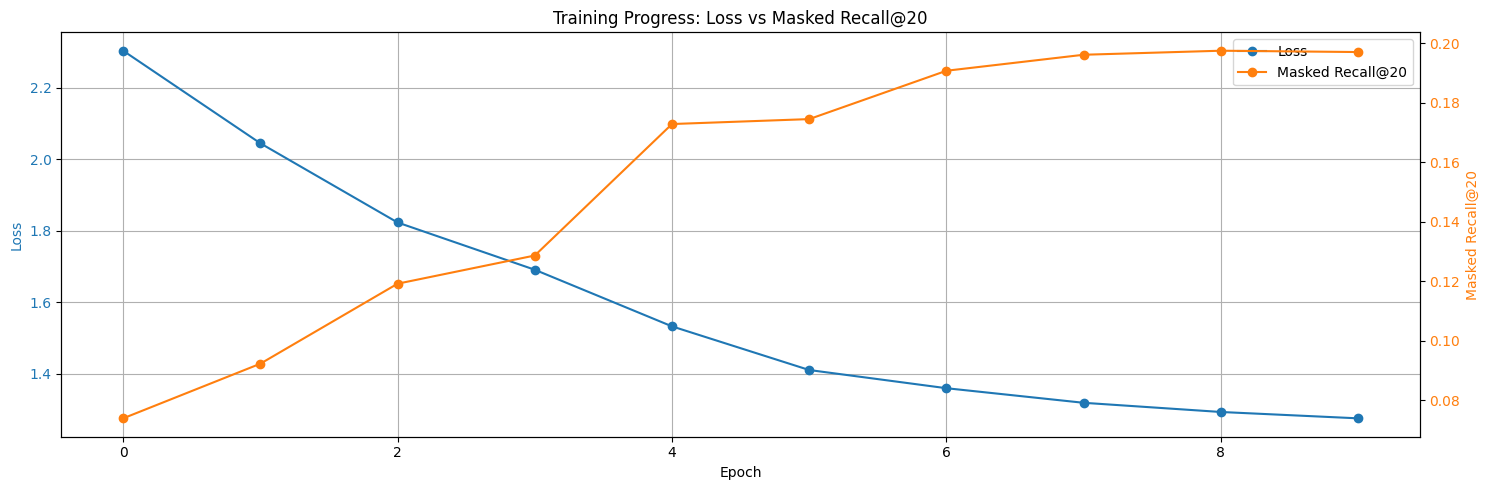

In [99]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt


# Training function
def train(
    model,
    dataloader,
    optimizer,
    device,
    item_lang_ids,
    item_year_ids,
    item_author_ids,
    info_nce=True,
    temperature=1,
):

    model.train()
    total = 0.0
    n = 0

    item_lang_ids = item_lang_ids.to(device)
    item_year_ids = item_year_ids.to(device)
    item_author_ids = item_author_ids.to(device)


    for batch in dataloader:
        u = batch["user_id"].to(device)                 # [B]
        i_pos = batch["pos_item_id"].to(device)         # [B]
        i_neg = batch["neg_item_id"].to(device)         # [B, Nneg]

        pos_lang = item_lang_ids[i_pos]                 # [B]
        pos_year = item_year_ids[i_pos]                 # [B]
        pos_author = item_author_ids[i_pos]             # [B]
        neg_lang = item_lang_ids[i_neg]                 # [B, Nneg]
        neg_year = item_year_ids[i_neg]                 # [B, Nneg]
        neg_author_id = item_author_ids[i_neg]          # [B, Nneg]

        optimizer.zero_grad(set_to_none=True)

        # scores
        s_pos = model(u, i_pos, pos_lang, pos_year, pos_author)     # [B]

        # expand users to match negatives
        u_neg = u.unsqueeze(1).expand_as(i_neg)         # [B, Nneg]
        s_neg = model(u_neg, i_neg, neg_lang, neg_year, neg_author_id) # [B, Nneg]

        # sampled softmax
        # candidate scores: [B, 1+Nneg], true class index is 0 (the positive)

        if not info_nce:
            loss = -F.logsigmoid(s_pos.unsqueeze(1) - s_neg).mean()
        else:
            scores = torch.cat([s_pos.unsqueeze(1), s_neg], dim=1)  # [B, 1+Nneg]
            scores = scores / temperature
            targets = torch.zeros(scores.size(0), dtype=torch.long, device=device)
            loss = F.cross_entropy(scores, targets)

        loss.backward()
        optimizer.step()

        total += loss.item()
        n += 1

    return total / max(n, 1)


# Device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("Using device:", device)

# Item-level metadata tensors (aligned to item_idx)
item_meta = (
    dataset[["item_idx", "lang_idx", "year_idx", "author_idx"]]
    .drop_duplicates("item_idx")
    .sort_values("item_idx")
)

item_lang_ids = torch.tensor(item_meta["lang_idx"].values, dtype=torch.long)
item_year_ids = torch.tensor(item_meta["year_idx"].values, dtype=torch.long)
item_author_ids = torch.tensor(item_meta["author_idx"].values, dtype=torch.long)

num_users = int(dataset["user_idx"].nunique())
num_items = int(dataset["item_idx"].nunique())
num_langs = int(dataset["lang_idx"].nunique())
num_year_buckets = int(dataset["year_idx"].nunique())
num_authors = int(dataset["author_idx"].nunique())

assert len(item_meta) == num_items
assert (item_meta["item_idx"].values == torch.arange(num_items).numpy()).all()


# 1) Build train_seen and eval_pos
train_seen = (
    train_df.groupby("user_idx")["item_idx"]
    .apply(set)
    .to_dict()
)

# choose split to evaluate on
# eval_df = val_df   # <-- change to test_df when model is trained
eval_df = test_df   # <-- change to val_df if you want validation

eval_pos = (
    eval_df[eval_df["label"] == 1]
    .groupby("user_idx")["item_idx"]
    .apply(set)
    .to_dict()
)

print("eval users:", len(eval_pos), "train users:", len(train_seen))

# model

model = TwoTowerModel(
    num_users=num_users,
    num_items=num_items,
    num_langs=num_langs,
    num_year_buckets=num_year_buckets,
    num_authors=num_authors,
    emb_dim=64,
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

# loop
num_epochs = 10
losses = []
recall20s  = []

# choose split to evaluate on
eval_df = test_df   # <-- change to val_df if you want validation

eval_pos = (
    eval_df[eval_df["label"] == 1]
    .groupby("user_idx")["item_idx"]
    .apply(set)
    .to_dict()
)

for epoch in range(0, num_epochs):
    loss = train(
        model,
        train_loader,
        optimizer,
        device,
        item_lang_ids,
        item_year_ids,
        item_author_ids,
        info_nce=True,
    )

    r20 = recall_at_k_mask_seen(
        model,
        eval_pos,
        train_seen,
        num_items,
        item_lang_ids,
        item_year_ids,
        item_author_ids,
        K=20,
        device=device,
        max_users=2000,
    )

    losses.append(loss)
    recall20s.append(r20)

    print(f"Epoch {epoch:02d} | loss: {loss:.4f} | masked recall@20: {r20:.4f}")

# plot (two y-axes since scales differ)
epochs = list(range(0, num_epochs))
fig, ax1 = plt.subplots(figsize=(15, 5))

# Left axis: Loss
color_loss = "tab:blue"
ax1.plot(epochs, losses, color=color_loss, marker="o", label="Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss", color=color_loss)
ax1.tick_params(axis="y", labelcolor=color_loss)
ax1.grid(True)

# Right axis: Recall@20
ax2 = ax1.twinx()
color_recall = "tab:orange"
ax2.plot(epochs, recall20s, color=color_recall, marker="o", label="Masked Recall@20")
ax2.set_ylabel("Masked Recall@20", color=color_recall)
ax2.tick_params(axis="y", labelcolor=color_recall)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.title("Training Progress: Loss vs Masked Recall@20")
plt.tight_layout()
plt.show()

#### Evaluate

In [103]:
import numpy as np
import torch

def recall_at_k_pop_mask_seen(eval_pos, train_seen, popular_items, K=20, max_users=None):
    users = list(eval_pos.keys())
    if max_users is not None:
        users = users[:max_users]

    recalls = []
    for u in users:
        pos_set = eval_pos.get(u, set())
        if not pos_set:
            continue

        seen = train_seen.get(u, set())

        recs = []
        for it in popular_items:
            if it not in seen:
                recs.append(it)
            if len(recs) >= K:
                break

        hits = sum((i in pos_set) for i in recs)
        recalls.append(hits / len(pos_set))

    return float(sum(recalls) / len(recalls)) if recalls else 0.0


# Build train_seen and eval_pos
train_seen = (
    train_df.groupby("user_idx")["item_idx"]
    .apply(set)
    .to_dict()
)

# choose split to evaluate on
eval_df = test_df   # <-- change to val_df if you want validation

eval_pos = (
    eval_df[eval_df["label"] == 1]
    .groupby("user_idx")["item_idx"]
    .apply(set)
    .to_dict()
)


# Popularity list from TRAIN positives (global)
popular_items = (
    train_df[train_df["label"] == 1]
    .groupby("item_idx")
    .size()
    .sort_values(ascending=False)
    .index.tolist()
)


# Compute both metrics on SAME users (cap optional)
MAX_USERS = 2000  # set None for all users (slower but best)

model_r20 = recall_at_k_mask_seen(
    model=model,
    eval_pos=eval_pos,
    train_seen=train_seen,
    num_items=num_items,
    item_lang_ids=item_lang_ids,
    item_year_ids=item_year_ids,
    item_author_ids=item_author_ids,
    K=20,
    device=device,
    max_users=MAX_USERS,
)

pop_r20 = recall_at_k_pop_mask_seen(
    eval_pos=eval_pos,
    train_seen=train_seen,
    popular_items=popular_items,
    K=20,
    max_users=MAX_USERS,
)

print(f"Masked Recall@20 (Model): {model_r20:.4f}")
print(f"Masked Recall@20 (Global_Popularity) : {pop_r20:.4f}")
print(f"Lift (abs): {model_r20 - pop_r20:+.4f}")
print(f"Lift (rel): {(model_r20 / pop_r20 - 1.0)*100:+.2f}%")

Masked Recall@20 (Model): 0.1971
Masked Recall@20 (Global_Popularity) : 0.0754
Lift (abs): +0.1217
Lift (rel): +161.31%


#### Inspect model

In [104]:
import numpy as np
import torch

@torch.no_grad()
def inspect_5_users(
    model,
    train_df,
    eval_df,                 # val_df or test_df
    item_info,
    item_lang_ids,           # torch.LongTensor [num_items]
    item_year_ids,           # torch.LongTensor [num_items]
    item_author_ids,         # torch.LongTensor [num_items]
    num_items,
    K=10,
    n_users=5,
    device="cpu",
    seed=42,
):
    model.eval()

    train_pos = (
        train_df[train_df["label"] == 1]
        .groupby("user_idx")["item_idx"]
        .apply(set)
        .to_dict()
    )
    eval_pos = (
        eval_df[eval_df["label"] == 1]
        .groupby("user_idx")["item_idx"]
        .apply(set)
        .to_dict()
    )

    users = list(eval_pos.keys())
    if not users:
        print("No eval positives to inspect.")
        return

    rng = np.random.default_rng(seed)
    chosen = rng.choice(users, size=min(n_users, len(users)), replace=False).tolist()

    # Precompute all item embeddings once
    item_lang_ids = item_lang_ids.to(device)
    item_year_ids = item_year_ids.to(device)
    item_author_ids = item_author_ids.to(device)
    all_item_ids = torch.arange(num_items, device=device, dtype=torch.long)
    all_item_embs = model.encode_item(all_item_ids, item_lang_ids, item_year_ids, item_author_ids)  # [I, D]

    info = item_info.set_index("item_idx")

    def fmt(i):
        r = info.loc[i]
        return f'{int(r.book_id)} | {str(r.title)[:80]} | lang={r.language_code} | year_bucket={r.year_bucket}'

    for u in chosen:
        seen = train_pos.get(u, set())
        held = eval_pos.get(u, set())

        user_id = torch.tensor([u], device=device, dtype=torch.long)
        user_emb = model.encode_user(user_id)  # [1,D]

        scores = (user_emb @ all_item_embs.T).squeeze(0) / model.scale

        # mask train-seen
        if seen:
            scores[torch.tensor(list(seen), device=device, dtype=torch.long)] = -1e9

        topk = torch.topk(scores, K, largest=True).indices.detach().cpu().tolist()
        hits = [i for i in topk if i in held]

        print("\n" + "="*100)
        print(f"user_idx={u} | train_pos={len(seen)} | eval_pos={len(held)} | hits_in_top{K}={len(hits)}")

        print("\nTrain history (first 15 positives):")
        for i in list(seen)[:15]:
            print("  H ", fmt(i))

        print(f"\nTop-{K} recommendations (masked train-seen):")
        for rank, i in enumerate(topk, 1):
            mark = "✅" if i in held else "  "
            print(f"  {mark} #{rank:02d} {fmt(i)}")

        print("\nHeld-out eval positives (first 15):")
        for i in list(held)[:15]:
            print("  T ", fmt(i))

    print("\nDone.")


# Map item_idx -> (book_id, title, language_code, year_bucket)
item_info = (
    dataset[["item_idx", "book_id", "language_code", "year_bucket", "primary_author"]]
    .drop_duplicates("item_idx")
    .merge(books[["book_id", "title"]], on="book_id", how="left")
    .sort_values("item_idx")
)

inspect_5_users(
    model=model,
    train_df=train_df,
    eval_df=val_df,
    item_info=item_info,
    item_lang_ids=item_lang_ids,
    item_year_ids=item_year_ids,
    item_author_ids=item_author_ids,
    num_items=num_items,
    K=10,
    n_users=5,
    device=device,
    seed=42,
)


user_idx=41298 | train_pos=24 | eval_pos=4 | hits_in_top10=0

Train history (first 15 positives):
  H  1710 | At Home: A Short History of Private Life | lang=eng | year_bucket=2010
  H  315 | Who Moved My Cheese? | lang=eng | year_bucket=1990
  H  4003 | Ben-Hur: A Tale of the Christ | lang=eng | year_bucket=1880
  H  83 | A Tale of Two Cities | lang=eng | year_bucket=1850
  H  86 | A Time to Kill | lang=eng | year_bucket=1980
  H  611 | The Silmarillion (Middle-Earth Universe) | lang=eng | year_bucket=1970
  H  1277 | The Case for Christ | lang=UNK | year_bucket=1980
  H  374 | A Short History of Nearly Everything | lang=en-US | year_bucket=2000
  H  375 | The Call of the Wild | lang=eng | year_bucket=1900
  H  123 | The Firm (Penguin Readers, Level 5) | lang=eng | year_bucket=1990
  H  935 | White Fang | lang=eng | year_bucket=1900
  H  778 | The Hunchback of Notre-Dame | lang=eng | year_bucket=1830
  H  514 | The Adventures of Sherlock Holmes | lang=eng | year_bucket=1890
  H  132 

In [105]:
author_counts = train_df[train_df["label"]==1]["author_idx"].value_counts()
print("num_authors:", author_counts.shape[0])
print("authors with <5 positives:", (author_counts < 5).mean())
print("authors with <20 positives:", (author_counts < 20).mean())
print("authors with <100 positives:", (author_counts < 100).mean())

num_authors: 1006
authors with <5 positives: 0.0
authors with <20 positives: 0.0009940357852882703
authors with <100 positives: 0.05467196819085487
